In [1]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv('DOE_3strategies_8scenarios_30seeds.csv')

# 你的 Pareto 函数（保持不变）
def pareto_non_dominated(df_group):
    metrics = ['Total_cost', 'nb_groups']
    scores = df_group[metrics].values
    n = len(scores)
    is_dominated = np.zeros(n, dtype=bool)
    for i in range(n):
        for j in range(n):
            if i == j: continue
            if all(scores[j] <= scores[i]) and any(scores[j] < scores[i]):
                is_dominated[i] = True
                break
    return df_group[~is_dominated].copy()

# 你的 factor_df
factor_df = pd.DataFrame([
    [1, 'Low', 'Periodic', 'Uniform', 30],
    [2, 'Low', 'Periodic', 'Clustered', 30],
    [3, 'Low', 'Aperiodic', 'Uniform', 30],
    [4, 'Low', 'Aperiodic', 'Clustered', 30],
    [5, 'High', 'Periodic', 'Uniform', 150],
    [6, 'High', 'Periodic', 'Clustered', 150],
    [7, 'High', 'Aperiodic', 'Uniform', 150],
    [8, 'High', 'Aperiodic', 'Clustered', 150]
], columns=['scenario_id', 'Density', 'Periodicity', 'Clustering', 'Expected_I'])

print("=== 🎯 场景分析开始 ===")

# ========================================
# 实验 1：权重扫描
# ========================================
scenarios = df['scenario_id'].unique()
weights = np.arange(0.1, 1.0, 0.1)

scenario_summary = df.groupby(['scenario_id', 'strategy']).agg({
    'Total_cost': 'mean', 
    'nb_groups': 'mean'
}).reset_index()

weight_results = []
for scenario_id in scenarios:
    scen_data = scenario_summary[scenario_summary['scenario_id'] == scenario_id]
    for w_cost in weights:
        scores = {}
        for _, row in scen_data.iterrows():
            strategy = row['strategy']
            score = w_cost * row['Total_cost'] + (1 - w_cost) * row['nb_groups']
            scores[strategy] = score
        best_strategy = min(scores, key=scores.get)
        weight_results.append({
            'scenario_id': scenario_id, 
            'w_cost': f"{w_cost:.1f}",
            'best': best_strategy
        })

weight_df = pd.DataFrame(weight_results)
weight_pivot = weight_df.pivot(index='scenario_id', columns='w_cost', values='best').fillna('')
print("\n📊 权重敏感性表 (复制到论文):")
print(weight_pivot.to_markdown())

# ========================================
# 实验 2：场景分解
# ========================================
scenario_perf = scenario_summary.merge(factor_df, on='scenario_id', how='left')

m1_data = scenario_perf[scenario_perf['strategy'] == 'M1']
m2_data = scenario_perf[scenario_perf['strategy'] == 'M2']
m1_m2_comparison = m1_data[['scenario_id', 'Total_cost', 'nb_groups', 'Density', 'Clustering']].\
                   merge(m2_data[['scenario_id', 'Total_cost', 'nb_groups']], 
                         on='scenario_id', suffixes=('_M1', '_M2'))

m1_m2_comparison['density_num'] = m1_m2_comparison['Density'].map({'Low': 0.2, 'High': 0.8})
m1_m2_comparison['clustering_num'] = m1_m2_comparison['Clustering'].map({'Uniform': 0, 'Clustered': 1})

if len(m1_m2_comparison) >= 2:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        m1_m2_comparison['density_num'], 
        m1_m2_comparison['Total_cost_M1'] - m1_m2_comparison['Total_cost_M2']
    )
    print(f"\n📈 回归分析: Δcost_M1-M2 = {slope:.2f}×density {intercept:+.1f} (R²={r_value**2:.3f})")

group_stats = scenario_perf.groupby(['Density', 'Clustering', 'strategy'])[['Total_cost', 'nb_groups']].mean().round(1)
print("\n📊 分组性能表:")
print(group_stats.to_markdown())

# ========================================
# 实验 3：经济影响
# ========================================
def business_score(row):
    cost = row['Total_cost']
    groups = row['nb_groups']
    setup_cost_per_group = 500
    dispatch_limit = 15
    overtime_penalty = 200
    return -(cost + groups * setup_cost_per_group + max(0, groups-dispatch_limit) * overtime_penalty)

scenario_summary['business_score'] = scenario_summary.apply(business_score, axis=1)

# 每个场景赢家
scenario_winners = scenario_summary.loc[scenario_summary.groupby('scenario_id')['business_score'].idxmax()]
print("\n🏆 业务赢家表:")
print(scenario_winners[['scenario_id', 'strategy', 'business_score', 'Total_cost', 'nb_groups']].round(1).to_markdown(index=False))

# 胜率统计
win_count = scenario_winners['strategy'].value_counts()
print(f"\n📊 总体胜率: {win_count.to_dict()}")

# ========================================
# LaTeX 兼容输出（纯文本）
# ========================================
print("\n=== 📄 论文 LaTeX 表格（手动复制）===")
print("\n权重表 (Table \\ref{tab:weights}):")
print(weight_pivot.to_string())

print("\n分组表 (Table \\ref{tab:groups}):")
print(group_stats.to_string())

print("\n赢家表 (Table \\ref{tab:winners}):")
print(scenario_winners[['scenario_id', 'strategy', 'business_score']].round(1).to_string(index=False))

print("\n✅ 分析完成！所有结果已输出，无需额外依赖")


=== 🎯 场景分析开始 ===

📊 权重敏感性表 (复制到论文):
|   scenario_id | 0.1   | 0.2   | 0.3   | 0.4   | 0.5   | 0.6   | 0.7   | 0.8   | 0.9   |
|--------------:|:------|:------|:------|:------|:------|:------|:------|:------|:------|
|             1 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             2 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             3 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             4 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             5 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             6 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             7 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |
|             8 | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    | M2    |

📈 回归分析: Δcost_M1-M2 = 7405.35×density +1444.7 (R²=0.783)

📊 分组性

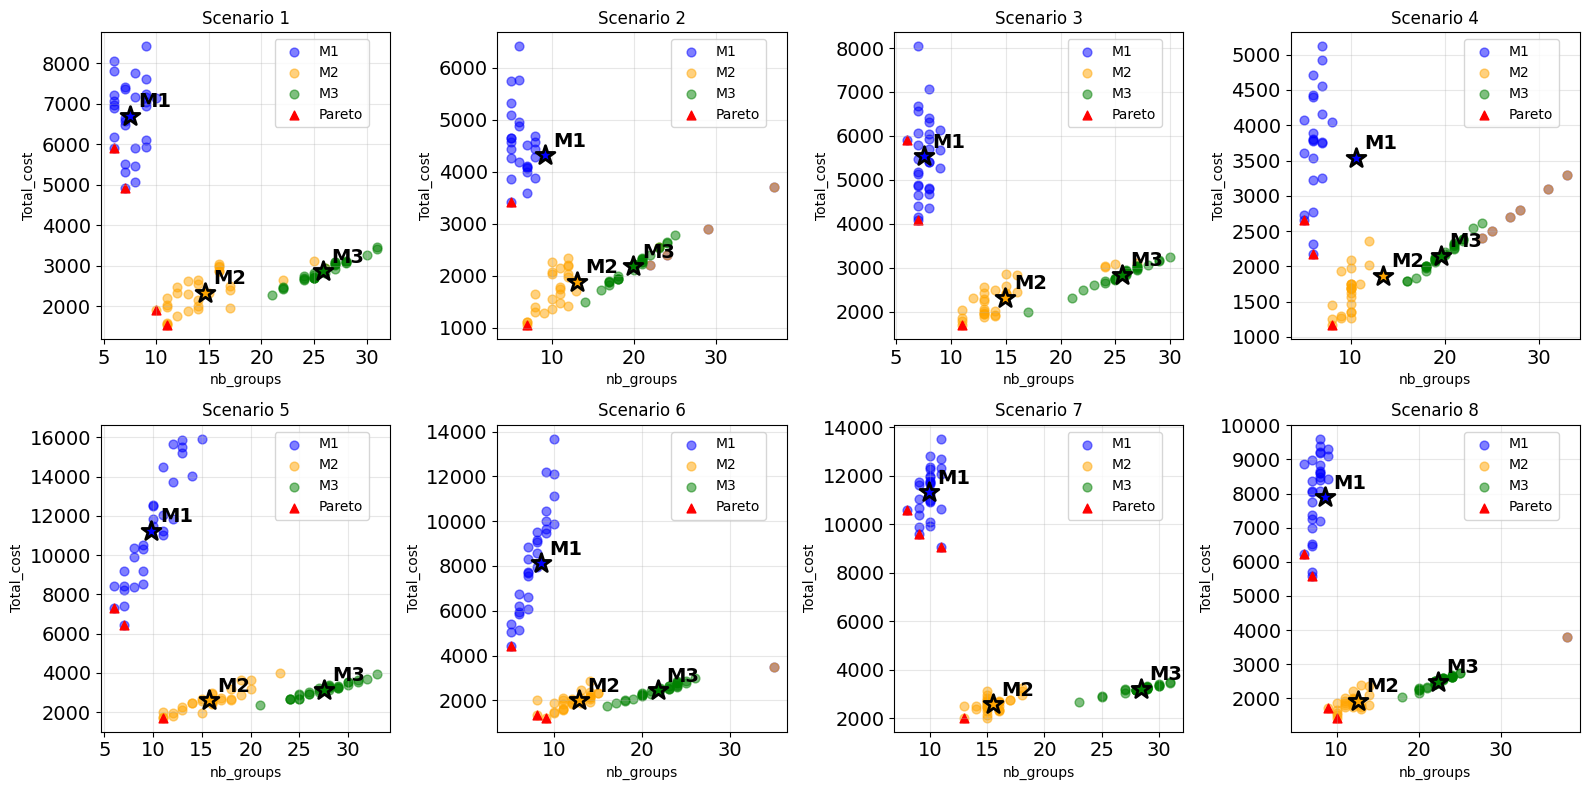

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//4, i%4]
    
    # 散点（同原代码）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
                  c=colors[strategy], alpha=0.5, s=40, label=strategy)
    
    # 均值★ + 标签（你的style！）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto红★
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', fontsize=14,
                    c='red', s=40, marker='^', ax=ax, label='Pareto')
    
    ax.set_title(f'Scenario {scen}')
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(0.95, 1))

plt.tight_layout()
plt.savefig('pareto_with_means_annotated.png', dpi=300, bbox_inches='tight')
plt.show()



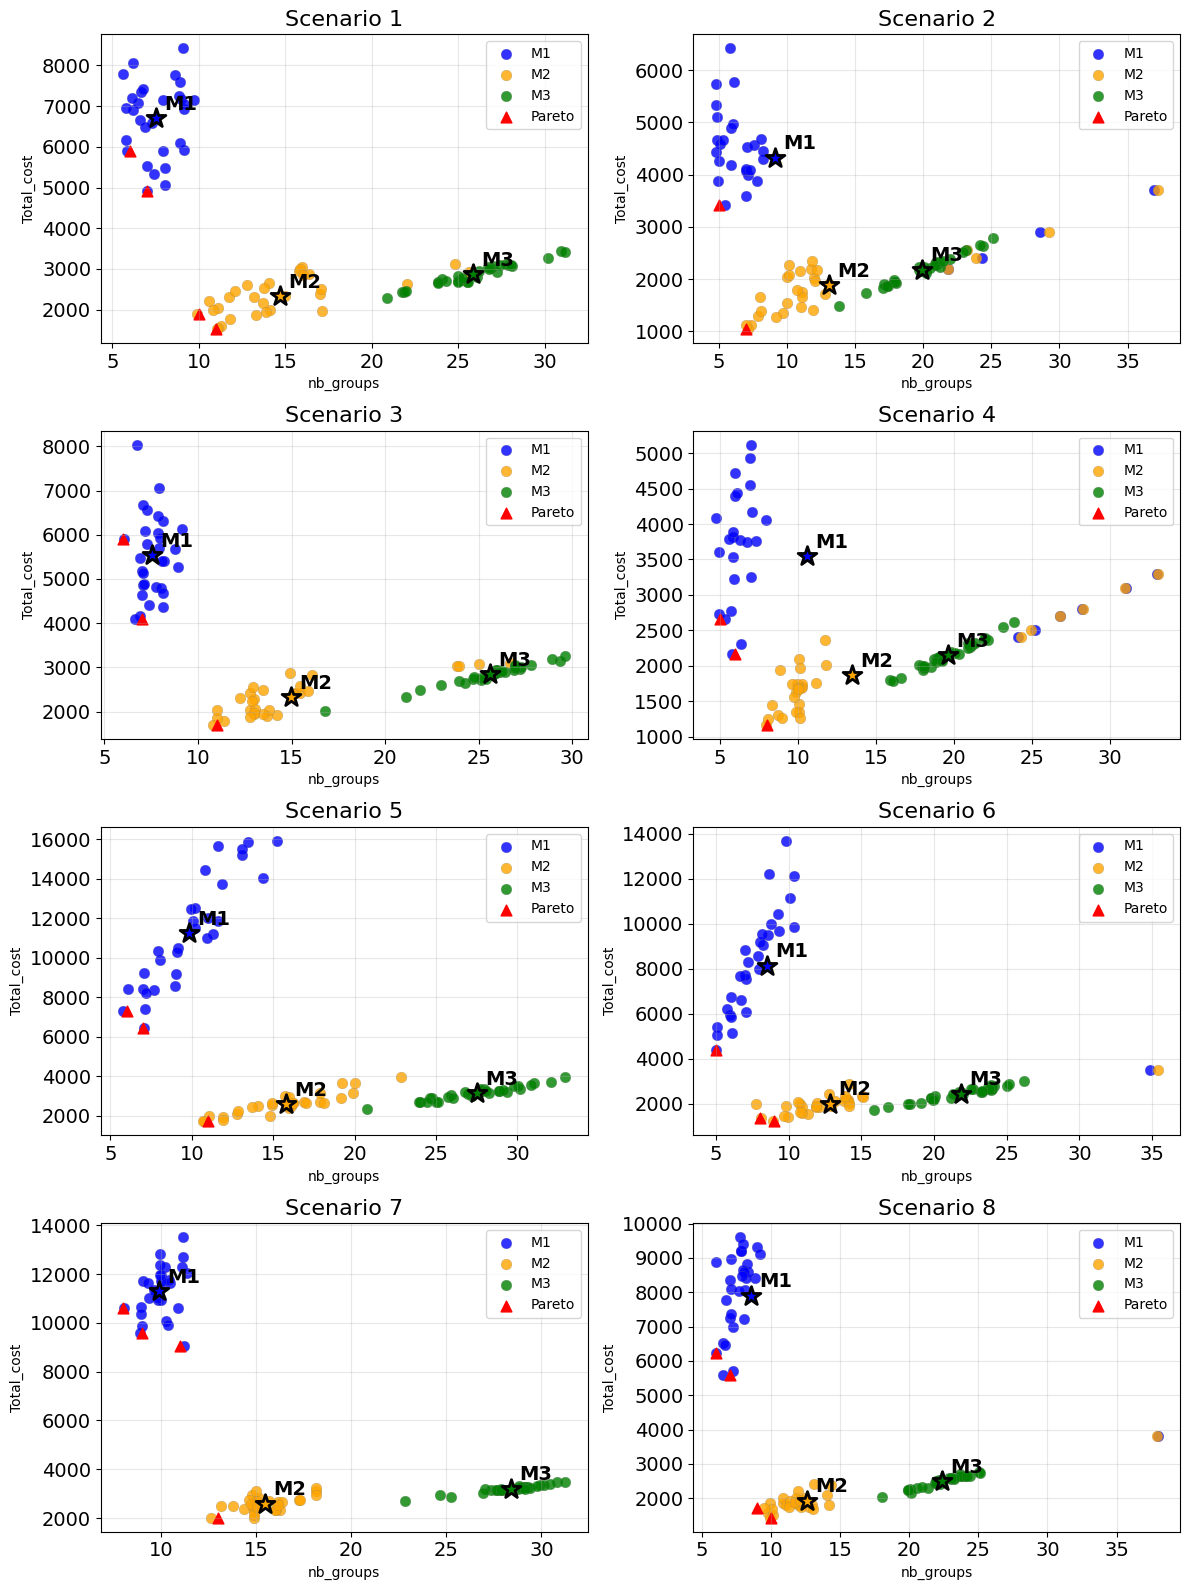

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(12, 16))  # 改为4行2列，更高更窄
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//2, i%2]  # 行优先：i//2为行，i%2为列
    
    # 散点（同原代码）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        # ax.scatter(strat_data['nb_groups'], strat_data['Total_cost'], 
        #           c=colors[strategy], alpha=0.5, s=40, label=strategy)
        jitter = np.random.normal(0, 0.2, len(strat_data))
        ax.scatter(strat_data['nb_groups'] + jitter, strat_data['Total_cost'], 
                c=colors[strategy], alpha=0.8, s=60, edgecolors='gray', linewidth=0.2,label=strategy)
    
    # 均值★ + 标签（你的style！）
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto红★（可选过滤）
    pareto_best = pareto_non_dominated(group)
    pareto_best.plot(x='nb_groups', y='Total_cost', kind='scatter', fontsize=14,
                    c='red', s=60, marker='^', ax=ax, label='Pareto')  # 改darkred更明显
                    
    
    ax.set_title(f'Scenario {scen}', fontsize=16)
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.0, 1))

plt.tight_layout()
plt.savefig('pareto_4x2_layout.png', dpi=300, bbox_inches='tight')
plt.show()

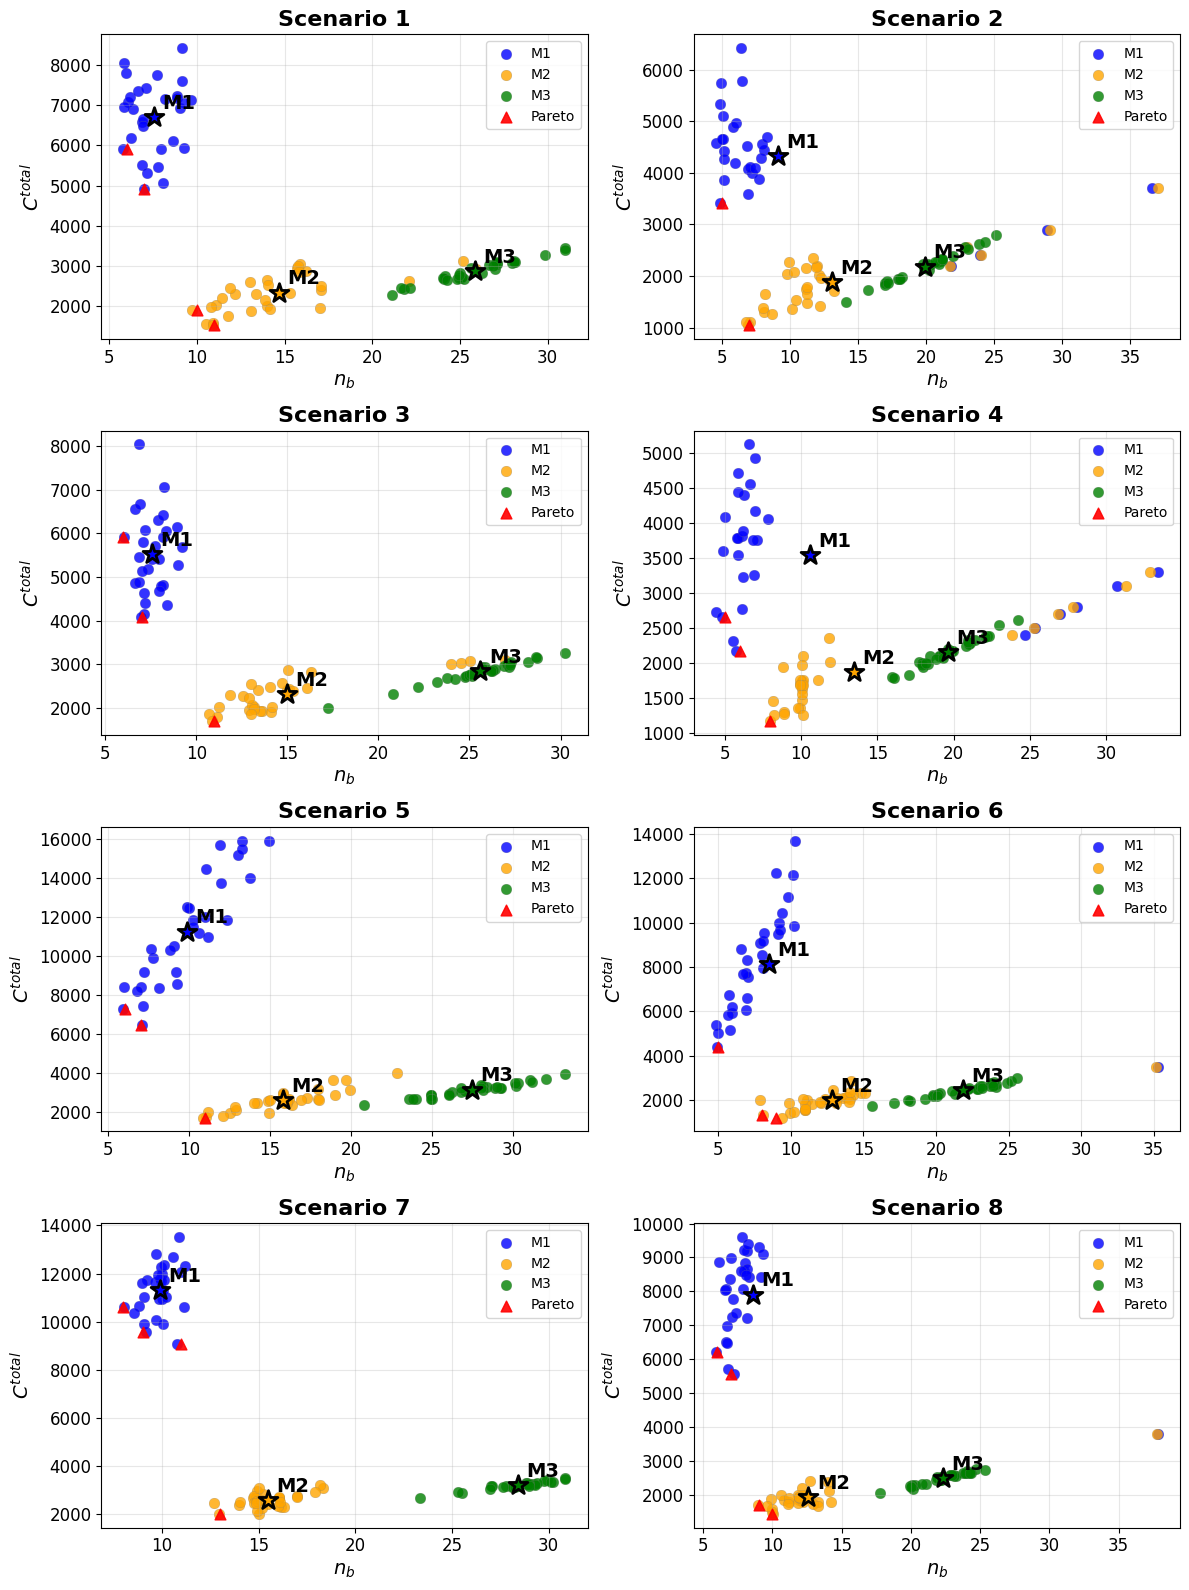

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
colors = {'M1':'blue', 'M2':'orange', 'M3':'green'}

for i, (scen, group) in enumerate(df.groupby('scenario_id')):
    ax = axes[i//2, i%2]
    
    # 散点
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        jitter = np.random.normal(0, 0.2, len(strat_data))
        ax.scatter(strat_data['nb_groups'] + jitter, strat_data['Total_cost'], 
                c=colors[strategy], alpha=0.8, s=60, edgecolors='gray', linewidth=0.2, label=strategy)
    
    # 均值★ + 标签
    for strategy in group['strategy'].unique():
        strat_data = group[group['strategy']==strategy]
        mean_x = strat_data['nb_groups'].mean()
        mean_y = strat_data['Total_cost'].mean()
        ax.scatter(mean_x, mean_y, color=colors[strategy], marker='*', 
                  s=200, edgecolors='black', linewidths=2, zorder=5)
        ax.annotate(strategy, xy=(mean_x, mean_y), xytext=(6, 6),
                   textcoords='offset points', fontsize=14, fontweight='bold')
    
    # Pareto：手动避免legend问题
    pareto_best = pareto_non_dominated(group)
    ax.scatter(pareto_best['nb_groups'], pareto_best['Total_cost'], 
               c='red', s=60, marker='^', label='Pareto', zorder=10, alpha=0.9)
    
    # 轴标签大一点 + title已大
    ax.set_xlabel('$n_{b}$', fontsize=14, fontweight='bold')
    ax.set_ylabel('$C^{total}$', fontsize=14, fontweight='bold')
    ax.set_title(f'Scenario {scen}', fontsize=16, fontweight='bold')

    # ← 新增：刻度字体大一点
    ax.tick_params(axis='both', labelsize=12)  # x/y轴刻度数字 fontsize=12
    ax.tick_params(axis='x', labelrotation=0)
    
    
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.0, 1))

plt.tight_layout()
# plt.savefig('pareto_4x2_larger_labels.png', dpi=300, bbox_inches='tight')
plt.show()